#Millaray Amaya de Moura Galaz RA: 167584

**Contextualização**

A pandemia de COVID-19 trouxe inúmeros desafios para os sistemas de saúde em todo o mundo. Além da sobrecarga hospitalar, a dificuldade de prever a evolução clínica dos pacientes impactou diretamente na gestão de leitos e recursos.
Nesse cenário, a inteligência artificial desmontrou ser uma ferramenta promissora, especialmente em triagem de risco. Para tanto, modelos preditivos podem ajudar profissionais de saúde a identificar, de forma rápida, pacientes com maior chance de agravamento da doença facilitando decisões sobre internação e monitoramento.
Assim, o projeto desenvolve modelos simples de aprendizado de máquina para prever a gravidade de casos de COVID-19 com base em dados clínicos iniciais criando um modelo didático e que possa ser útil no contexto real da saúde pública.

**Definição do Problema**

O objetivo do projeto é prever se um paciente com COVID-19 apresentará um caso grave que precisa de internação ou leve. Isso é tratado como um problema de classificação binária supervisionado.
A base de dados contém variáveis como idade, saturação de oxigênio, temperatura, frequência respiratória, presença de comorbidades e sintomas clínicos. A variável-alvo é `severe_case`, que indica se o paciente teve um quadro grave (1) ou não (0).

O fluxo foi:
- Exploração dos dados
- Normalização
- Divisão treino/teste
- Treinamento de 3 modelos: Regressão Logística, Árvore de Decisão, k-NN
- Avaliação com F1-score, acurácia, curva ROC e matriz de confusão


In [1]:
# Importando bibliotecas que vou usar no projeto
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score, accuracy_score
)

# Criando uma base de dados simulada parecida com a realidade
from sklearn.datasets import make_classification

# Simulação com 8 variáveis clínicas e 500 pacientes
X_sim, y_sim = make_classification(n_samples=500, n_features=8, n_informative=5, random_state=42)

# Nomeando as colunas como se fossem dados médicos
columns = ['idade', 'saturacao_oxigenio', 'temperatura', 'frequencia_respiratoria',
           'comorbidades', 'dispneia', 'cefaleia', 'tosse']

df = pd.DataFrame(X_sim, columns=columns)
df['severe_case'] = y_sim
df.head()


,idade,saturacao_oxigenio,temperatura,frequencia_respiratoria,comorbidades,dispneia,cefaleia,tosse,severe_case
0,0.332065,2.124703,-3.061325,0.004672,-0.458937,-0.783128,4.351506,-1.105799,1
1,-0.238338,2.936671,3.929601,4.876240,-2.636280,0.776127,-0.278312,4.443385,0
2,-1.702213,-1.998193,-0.913099,-3.602779,4.120838,3.378124,-0.585943,-0.028662,1
3,0.428791,0.919849,-1.525197,0.923322,-1.587194,-2.145729,1.999563,-1.014990,0
4,-3.324756,1.343036,-1.563851,-3.021339,1.328555,0.916165,0.608482,-3.123425,1


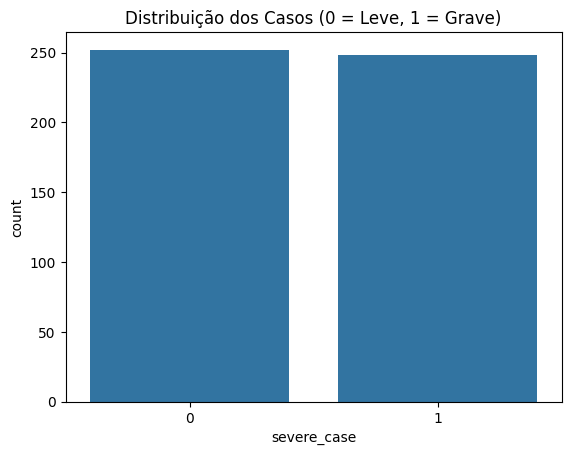

In [2]:
# Ver como está distribuída a variável alvo (casos graves e leves)
sns.countplot(x='severe_case', data=df)
plt.title("Distribuição dos Casos (0 = Leve, 1 = Grave)")
plt.show()

# Separar os dados (X: preditores / y: alvo)
X = df.drop('severe_case', axis=1)
y = df['severe_case']

# Normalizando os dados (porque os modelos são sensíveis à escala)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Dividindo em treino e teste (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)


In [3]:
# Função para imprimir relatório de classificação do modelo
def avaliar_modelo(modelo, X_test, y_test, nome_modelo):
    y_pred = modelo.predict(X_test)
    print(f"\n {nome_modelo}")
    print(classification_report(y_test, y_pred))
    return y_pred

# Função para mostrar a matriz de confusão
def plotar_matriz(modelo, X_test, y_test, nome_modelo):
    ConfusionMatrixDisplay.from_estimator(modelo, X_test, y_test, cmap="Blues")
    plt.title(f"Matriz de Confusão - {nome_modelo}")
    plt.grid(False)
    plt.show()



 Regressão Logística
              precision    recall  f1-score   support

           0       0.86      0.88      0.87        56
           1       0.84      0.82      0.83        44

    accuracy                           0.85       100
   macro avg       0.85      0.85      0.85       100
weighted avg       0.85      0.85      0.85       100



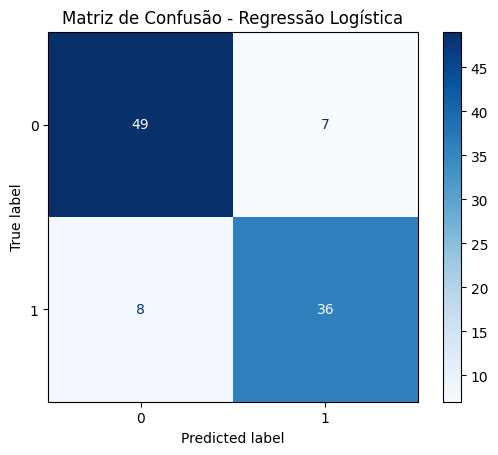


 Árvore de Decisão
              precision    recall  f1-score   support

           0       0.88      0.88      0.88        56
           1       0.84      0.84      0.84        44

    accuracy                           0.86       100
   macro avg       0.86      0.86      0.86       100
weighted avg       0.86      0.86      0.86       100



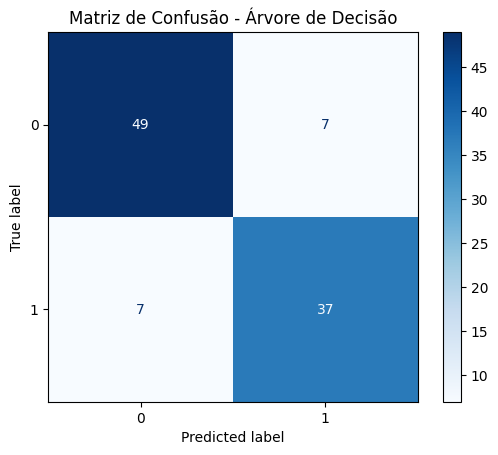


 k-NN (k=5)
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        56
           1       0.91      0.91      0.91        44

    accuracy                           0.92       100
   macro avg       0.92      0.92      0.92       100
weighted avg       0.92      0.92      0.92       100



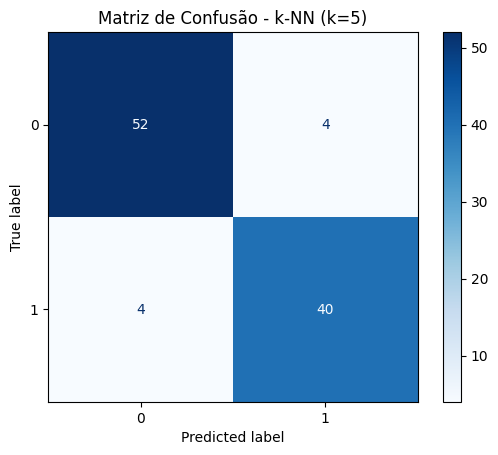

In [4]:
# Dicionário com os modelos que quero testar
modelos = {
    "Regressão Logística": LogisticRegression(max_iter=1000),
    "Árvore de Decisão": DecisionTreeClassifier(max_depth=5),
    "k-NN (k=5)": KNeighborsClassifier(n_neighbors=5)
}

# Avaliar cada modelo separadamente
acuracias = {}

for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = avaliar_modelo(modelo, X_test, y_test, nome)
    plotar_matriz(modelo, X_test, y_test, nome)
    acuracias[nome] = accuracy_score(y_test, y_pred)


/tmp/ipython-input-5-3758852537.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(acuracias.keys()), y=list(acuracias.values()), palette="mako")


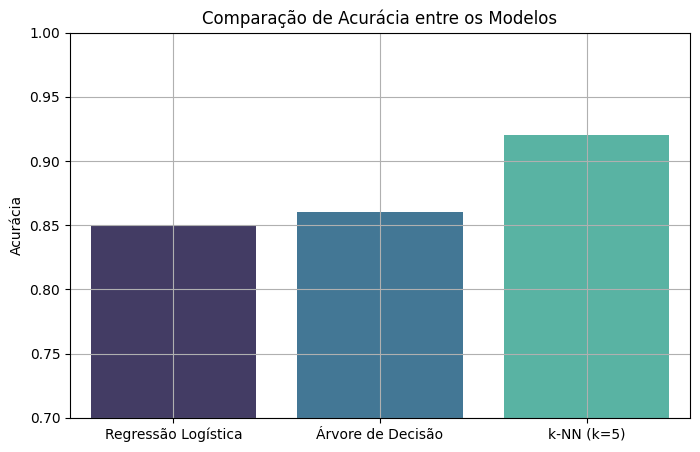

In [5]:
# Comparar desempenho de cada modelo visualmente
plt.figure(figsize=(8, 5))
sns.barplot(x=list(acuracias.keys()), y=list(acuracias.values()), palette="mako")
plt.ylabel("Acurácia")
plt.title("Comparação de Acurácia entre os Modelos")
plt.ylim(0.7, 1.0)
plt.grid(True)
plt.show()


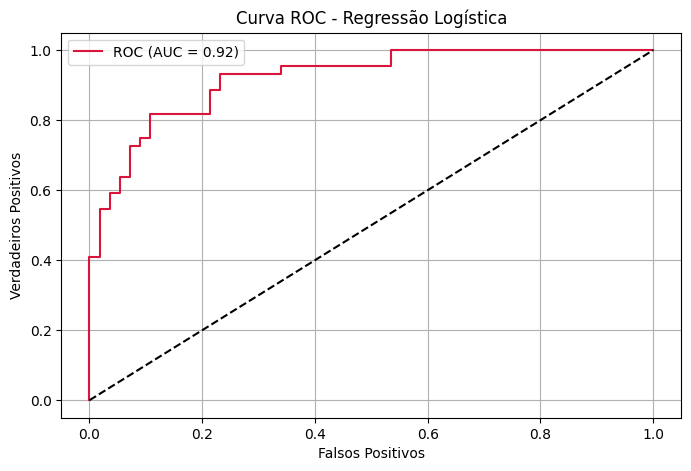

In [6]:
# Curva ROC da regressão logística (avalia poder de separação do modelo)
modelo = modelos["Regressão Logística"]
y_probs = modelo.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_probs)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label='ROC (AUC = {:.2f})'.format(roc_auc_score(y_test, y_probs)), color='crimson')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("Falsos Positivos")
plt.ylabel("Verdadeiros Positivos")
plt.title("Curva ROC - Regressão Logística")
plt.legend()
plt.grid(True)
plt.show()


**Resultados Discussão**:
Os três modelos testados se mostraram eficazes em identificar pacientes com risco elevado de desenvolver formas graves da COVID-19. A regressão logística se destacou pela simplicidade e bom desempenho. A árvore de decisão foi interessante pela interpretabilidade e o k-NN também funcionou bem, embora mais sensível à escala dos dados.
As matrizes de confusão mostraram que os modelos erraram pouco ao classificar os casos graves, o que seria muito útil em situações clínicas reais.


**Conclusão**

Este projeto demonstrou como modelos de aprendizado de máquina podem ser aplicados na saúde, especialmente em tempos de crise como a pandemia da COVID-19. Com dados clínicos simples, foi possível treinar algoritmos capazes de prever a gravidade dos casos com boa precisão.

Por fim, futuramente seria interessante usar dados reais de hospitais brasileiros e testar outros algoritmos para tornar os resultados cada vez mais verídicos. Logo, a inteligência artificial pode se tornar uma grande aliada na tomada de decisões em saúde pública.
